In [1]:
import sys
import deeplabcut
import torch

print("Python executable:", sys.executable)
print("DeepLabCut:", deeplabcut.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python executable: /home/aghammd/venvs/deeplabcut/bin/python
DeepLabCut: 3.0.2
PyTorch: 2.14.1+cu126
CUDA available: True
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


# Stage 4: DeepLabCut Fundamentals

## Objectives

In this stage, we will learn how to use DeepLabCut (DLC) for markerless pose estimation.

Unlike pretrained general-purpose pose-estimation models such as MoveNet, DeepLabCut provides a flexible framework for defining and tracking specific body parts.

We will focus on:

- Understanding the DeepLabCut architecture.
- Exploring pretrained human pose-estimation models.
- Running pose estimation on walking videos.
- Extracting and visualizing body landmarks.
- Understanding prediction confidence and reliability.
- Using detected landmarks for lower-limb joint-angle estimation.

Our initial experiments will use the sagittal walking video:

`data/raw/sagittal_walking.mp4`

We will initially use pretrained models, without creating a custom training dataset or manually annotating frames.

In [2]:
import deeplabcut
import inspect

print("DLC version:", deeplabcut.__version__)

print("SuperAnimal inference available:", hasattr(deeplabcut, "video_inference_superanimal"))

if hasattr(deeplabcut, "video_inference_superanimal"):
    print("SuperAnimal inference function signature:")
    print(inspect.signature(deeplabcut.video_inference_superanimal))

DLC version: 3.0.2
SuperAnimal inference available: True
SuperAnimal inference function signature:
(videos: 'str | list', superanimal_name: 'str', model_name: 'str', detector_name: 'str | None' = None, scale_list: 'list | None' = None, video_extensions: 'str | Sequence[str] | None' = None, dest_folder: 'str | Path | None' = None, cropping: 'list[int] | None' = None, video_adapt: 'bool' = False, plot_trajectories: 'bool' = False, batch_size: 'int' = 1, detector_batch_size: 'int' = 1, pcutoff: 'float' = 0.1, adapt_iterations: 'int' = 1000, pseudo_threshold: 'float' = 0.1, bbox_threshold: 'float' = 0.9, detector_epochs: 'int' = 4, pose_epochs: 'int' = 4, max_individuals: 'int' = 10, video_adapt_batch_size: 'int' = 8, device: 'str | None' = 'auto', customized_pose_checkpoint: 'str | None' = None, customized_detector_checkpoint: 'str | None' = None, customized_model_config: 'str | None' = None, plot_bboxes: 'bool' = True, create_labeled_video: 'bool' = True, fmpose_return_3d: 'bool' = False

## SuperAnimal-Human: RTMPose-X

We will use the pretrained SuperAnimal-Human model provided by DeepLabCut.

The selected configuration is:

- **SuperAnimal:** `superanimal_humanbody`
- **Pose model:** `rtmpose_x`
- **Person detector:** `fasterrcnn_mobilenet_v3_large_fpn`
- **Inference type:** Top-down
- **Keypoint format:** 17 COCO-style body landmarks

### How top-down pose estimation works

A top-down pose-estimation pipeline has two main stages:

1. **Person detection:** An object detector identifies the bounding box containing the person.
2. **Pose estimation:** The pose model processes the detected person and predicts the locations of the body keypoints.

We will initially use zero-shot inference, meaning that we will evaluate the pretrained model without training or adapting it to our video.

In [3]:
from pathlib import Path

project_root = Path.cwd()  # Assuming the current working directory is the project root

if not (project_root / "data" / "raw").exists():
    project_root = project_root.parent  # Move up one directory if "data/raw" doesn't exist

video_path = project_root / "data" / "raw" / "sagittal_walking.mp4"
output_dir = project_root / "data" / "processed" / "deeplabcut"

output_dir.mkdir(parents=True, exist_ok=True)  # Create the output directory if it doesn't exist

print("Project root:", project_root)
print("Video exists:", video_path.exists())
print("Video path:", video_path)
print("Output directory:", output_dir)

assert video_path.exists(), f"Video file does not exist: {video_path}"

Project root: /home/aghammd/Desktop/Programming/markerless-pose-estimation-lab
Video exists: True
Video path: /home/aghammd/Desktop/Programming/markerless-pose-estimation-lab/data/raw/sagittal_walking.mp4
Output directory: /home/aghammd/Desktop/Programming/markerless-pose-estimation-lab/data/processed/deeplabcut


In [4]:
import deeplabcut
import torch
import time

print("CUDA available:", torch.cuda.is_available())

start_time = time.time()

results = deeplabcut.video_inference_superanimal(
    videos=[str(video_path)],
    superanimal_name="superanimal_humanbody",
    model_name="rtmpose_x",
    detector_name="fasterrcnn_mobilenet_v3_large_fpn",
    video_adapt=False,
    batch_size=1,
    detector_batch_size=1,
    device="auto",
    dest_folder=str(output_dir),
    create_labeled_video=True,
)

elapsed_time = time.time() - start_time

print(f"Inference completed in {elapsed_time:.2f} seconds.")
print("Result type:", type(results))
print("Output directory:", output_dir)

Found invalid empty/null/None value for `Task` in the project config. This is only supported for legacy compatibility. Treating `Task` as unset and using the field default instead.
Found invalid empty/null/None value for `scorer` in the project config. This is only supported for legacy compatibility. Treating `scorer` as unset and using the field default instead.
Found invalid empty/null/None value for `date` in the project config. This is only supported for legacy compatibility. Treating `date` as unset and using the field default instead.
Found invalid empty/null/None value for `multianimalproject` in the project config. This is only supported for legacy compatibility. Treating `multianimalproject` as unset and using the field default instead.
Found invalid empty/null/None value for `project_path` in the project config. This is only supported for legacy compatibility. Treating `project_path` as unset and using the field default instead.
Found invalid empty/null/None value for `video_

CUDA available: True
Running video inference on ['/home/aghammd/Desktop/Programming/markerless-pose-estimation-lab/data/raw/sagittal_walking.mp4'] with superanimal_humanbody_rtmpose_x
Using pytorch for model rtmpose_x
Processing video /home/aghammd/Desktop/Programming/markerless-pose-estimation-lab/data/raw/sagittal_walking.mp4
Starting to analyze /home/aghammd/Desktop/Programming/markerless-pose-estimation-lab/data/raw/sagittal_walking.mp4
Video metadata: 
  Overall # of frames:    406
  Duration of video [s]:  13.53
  fps:                    30.0
  resolution:             w=1920, h=1080

Running detector with batch size 1


100%|██████████| 406/406 [00:10<00:00, 36.91it/s]


Running pose prediction with batch size 1


100%|██████████| 406/406 [00:04<00:00, 90.33it/s] 


Saving results to /home/aghammd/Desktop/Programming/markerless-pose-estimation-lab/data/processed/deeplabcut
Saving results in /home/aghammd/Desktop/Programming/markerless-pose-estimation-lab/data/processed/deeplabcut/sagittal_walking_superanimal_humanbody_rtmpose_x_fasterrcnn_mobilenet_v3_large_fpn.h5 and /home/aghammd/Desktop/Programming/markerless-pose-estimation-lab/data/processed/deeplabcut/sagittal_walking_superanimal_humanbody_rtmpose_x_fasterrcnn_mobilenet_v3_large_fpn_full.pickle
Duration of video [s]: 13.53, recorded with 30.0 fps!
Overall # of frames: 406 with cropped frame dimensions: 1920 1080
Generating frames and creating video.


100%|██████████| 406/406 [00:04<00:00, 94.01it/s] 

Video with predictions was saved as /home/aghammd/Desktop/Programming/markerless-pose-estimation-lab/data/processed/deeplabcut/sagittal_walking_superanimal_humanbody_rtmpose_x_fasterrcnn_mobilenet_v3_large_fpn_labeled_before_adapt.mp4
Inference completed in 21.11 seconds.
Result type: <class 'dict'>
Output directory: /home/aghammd/Desktop/Programming/markerless-pose-estimation-lab/data/processed/deeplabcut


## Inspecting DeepLabCut Prediction Data

DeepLabCut stores pose-estimation results in an HDF5 (`.h5`) file.

The file contains predictions for each detected body landmark across video frames.

For each landmark, we are interested in three values:

- **x:** Horizontal image coordinate.
- **y:** Vertical image coordinate.
- **likelihood:** Model confidence associated with the prediction.

We will inspect the DataFrame structure before extracting individual landmarks.

In [5]:
import pandas as pd

h5_files = list(output_dir.glob("*.h5"))

assert len(h5_files) > 0, "No .h5 files found in the output directory."

prediction_file = h5_files[0]

df = pd.read_hdf(prediction_file)

print("Prediction file:", prediction_file.name)
print("DataFrame shape:", df.shape)
print("\nColumn structure:")
print(df.columns)

print("\nFirst five rows:")
display(df.head())

Prediction file: sagittal_walking_superanimal_humanbody_rtmpose_x_fasterrcnn_mobilenet_v3_large_fpn.h5
DataFrame shape: (406, 510)

Column structure:
MultiIndex([('superanimal_humanbody_rtmpose_x_fasterrcnn_mobilenet_v3_large_fpn', ...),
            ('superanimal_humanbody_rtmpose_x_fasterrcnn_mobilenet_v3_large_fpn', ...),
            ('superanimal_humanbody_rtmpose_x_fasterrcnn_mobilenet_v3_large_fpn', ...),
            ('superanimal_humanbody_rtmpose_x_fasterrcnn_mobilenet_v3_large_fpn', ...),
            ('superanimal_humanbody_rtmpose_x_fasterrcnn_mobilenet_v3_large_fpn', ...),
            ('superanimal_humanbody_rtmpose_x_fasterrcnn_mobilenet_v3_large_fpn', ...),
            ('superanimal_humanbody_rtmpose_x_fasterrcnn_mobilenet_v3_large_fpn', ...),
            ('superanimal_humanbody_rtmpose_x_fasterrcnn_mobilenet_v3_large_fpn', ...),
            ('superanimal_humanbody_rtmpose_x_fasterrcnn_mobilenet_v3_large_fpn', ...),
            ('superanimal_humanbody_rtmpose_x_fasterrcnn_m

scorer      superanimal_humanbody_rtmpose_x_fasterrcnn_mobilenet_v3_large_fpn  \
individuals                                                           animal0   
bodyparts                                                                nose   
coords                                                                      x   
0                                                  1069.671875                  
1                                                  1070.078125                  
2                                                  1071.111084                  
3                                                  1070.267334                  
4                                                  1067.175293                  

scorer                                                                  \
individuals                                                              
bodyparts                              left_eye                          
coords                y likelihood            x           y likelihood   
0            184.960938   0.748618  1070.722168  169.199219   0.749310   
1            190.656250   0.776640  1071.125000  174.953125   0.561953   
2            195.647141   0.606905  1072.166626  178.751297   0.775033   
3            197.079422   0.842681  1070.267334  181.161453   0.781767   
4            199.156250   0.876382  1067.175293  182.364578   0.502326   

scorer                                                        ...             \
individuals                                                   ...    animal9   
bodyparts      right_eye                            left_ear  ...  left_knee   
coords                 x           y likelihood            x  ... likelihood   
0            1061.269043  164.996094   0.726062  1008.751709  ...       -1.0   
1            1062.750000  170.765625   0.980467  1012.500000  ...       -1.0   
2            1062.666626  174.527344   0.711035  1010.944458  ...       -1.0   
3            1060.720459  177.977859   0.824711  1005.560791  ...       -1.0   
4            1057.722168  179.216141   0.939054  1032.513916  ...       -1.0   

scorer                                                                         \
individuals                                                                     
bodyparts   right_knee                 left_ankle                 right_ankle   
coords               x    y likelihood          x    y likelihood           x   
0                 -1.0 -1.0       -1.0       -1.0 -1.0       -1.0        -1.0   
1                 -1.0 -1.0       -1.0       -1.0 -1.0       -1.0        -1.0   
2                 -1.0 -1.0       -1.0       -1.0 -1.0       -1.0        -1.0   
3                 -1.0 -1.0       -1.0       -1.0 -1.0       -1.0        -1.0   
4                 -1.0 -1.0       -1.0       -1.0 -1.0       -1.0        -1.0   

scorer                       
individuals                  
bodyparts                    
coords         y likelihood  
0           -1.0       -1.0  
1           -1.0       -1.0  
2           -1.0       -1.0  
3           -1.0       -1.0  
4           -1.0       -1.0  

[5 rows x 510 columns]

In [6]:
print("Column levels:", df.columns.nlevels)

for level in range(df.columns.nlevels):
    print(f"Level {level}:", df.columns.get_level_values(level).unique().tolist())

Column levels: 4
Level 0: ['superanimal_humanbody_rtmpose_x_fasterrcnn_mobilenet_v3_large_fpn']
Level 1: ['animal0', 'animal1', 'animal2', 'animal3', 'animal4', 'animal5', 'animal6', 'animal7', 'animal8', 'animal9']
Level 2: ['nose', 'left_eye', 'right_eye', 'left_ear', 'right_ear', 'left_shoulder', 'right_shoulder', 'left_elbow', 'right_elbow', 'left_wrist', 'right_wrist', 'left_hip', 'right_hip', 'left_knee', 'right_knee', 'left_ankle', 'right_ankle']
Level 3: ['x', 'y', 'likelihood']


In [7]:
print("Number of predictions:", len(df))
print("First frame indices:", df.index[:10].tolist())
print("Last frame index:", df.index[-1])

Number of predictions: 406
First frame indices: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Last frame index: 405


In [8]:
scorer = df.columns.get_level_values("scorer")[0]
print("Scorer:", scorer)

individuals = df.columns.get_level_values("individuals").unique()
print("Individuals:", individuals.tolist())

for individual in individuals:

    individual_data = df[scorer][individual]

    valid_frames = (
        (individual_data["nose"]["likelihood"] >= 0) &
        (individual_data["nose"]["x"] >= 0) &
        (individual_data["nose"]["y"] >= 0)
    ).sum()

    print(
        f"{individual}: "
        f"{valid_frames}/{len(df)} valid frames"
    )

Scorer: superanimal_humanbody_rtmpose_x_fasterrcnn_mobilenet_v3_large_fpn
Individuals: ['animal0', 'animal1', 'animal2', 'animal3', 'animal4', 'animal5', 'animal6', 'animal7', 'animal8', 'animal9']
animal0: 406/406 valid frames
animal1: 0/406 valid frames
animal2: 0/406 valid frames
animal3: 0/406 valid frames
animal4: 0/406 valid frames
animal5: 0/406 valid frames
animal6: 0/406 valid frames
animal7: 0/406 valid frames
animal8: 0/406 valid frames
animal9: 0/406 valid frames


In [9]:
lower_body_parts = [
    "left_hip",
    "right_hip",
    "left_knee",
    "right_knee",
    "left_ankle",
    "right_ankle"
]

animal_data = df[scorer]["animal0"]

lower_body_data = animal_data[lower_body_parts]

display(lower_body_data.head(10))

bodyparts     left_hip                           right_hip              \
coords               x           y likelihood            x           y   
0          1004.550354  458.164062   0.328049   985.644104  456.062500   
1          1004.125000  460.750000   0.324526   987.375000  458.656250   
2           999.333313  467.036469   0.348360   989.833313  463.868500   
3          1000.256958  467.684906   0.338448   990.710083  465.562500   
4          1002.053833  467.822906   0.345333   992.600708  464.674469   
5          1005.218750  469.320312   0.334886   995.859375  467.242188   
6          1007.375000  464.286469   0.309267   999.083313  463.250000   
7          1007.888916  465.460938   0.328906  1000.694458  465.460938   
8          1010.395813  462.078125   0.331686  1001.302063  462.078125   
9           998.255188  462.958344   0.308413  1004.411438  459.880219   

bodyparts               left_knee                          right_knee  \
coords    likelihood            x           y likelihood            x   
0           0.344354  1068.621582  598.968750   0.757320   958.335083   
1           0.346650  1062.750000  608.359375   0.713324   948.640625   
2           0.342295  1059.500000  614.875000   0.689817   945.500000   
3           0.377153  1059.659668  618.375000   0.613227   945.097229   
4           0.342381  1060.873291  616.848938   0.648483   949.536438   
5           0.347995  1061.375000  616.867188   0.514814   959.461792   
6           0.314127  1060.234375  615.609375   0.746442   976.281250   
7           0.359969  1055.166626  617.507812   0.518323   996.583313   
8           0.341931  1048.791626  623.953125   0.512831  1022.520813   
9           0.342584  1031.088501  635.333313   0.453280  1043.401001   

bodyparts                          left_ankle                         \
coords              y likelihood            x           y likelihood   
0          629.441406   0.511065  1090.678833  781.804688   0.629162   
1          632.437500   0.579674  1114.046875  785.281250   0.606041   
2          631.770813   0.495147  1123.888916  789.113281   0.500101   
3          635.354187   0.535764  1116.940918  795.595032   0.655381   
4          635.739563   0.537346  1107.088501  800.507812   0.495088   
5          637.648438   0.568311  1092.572876  801.820312   0.672154   
6          639.447937   0.656945  1076.817749  801.135437   0.622805   
7          642.164062   0.757305  1061.333374  805.511719   0.554661   
8          639.128906   0.647915  1045.760376  806.062500   0.606049   
9          638.411438   0.813106  1029.036499  810.786438   0.625183   

bodyparts right_ankle                         
coords              x           y likelihood  
0          899.515625  820.683594   0.511584  
1          882.687500  819.828125   0.533370  
2          865.277771  817.625000   0.666867  
3          850.689209  813.635437   0.604994  
4          838.199646  807.854187   0.574942  
5          830.510437  799.742188   0.564492  
6          831.177063  789.734375   0.628109  
7          837.277771  779.828125   0.614806  
8          849.739563  767.617188   0.573640  
9          871.026062  759.484375   0.479102

In [10]:
confidence_stats = {}

for bodypart in lower_body_parts:

    likelihood = animal_data[bodypart]["likelihood"]

    valid_likelihood = likelihood[likelihood >= 0]

    confidence_stats[bodypart] = {
        "valid_frames": len(valid_likelihood),
        "mean_confidence": valid_likelihood.mean(),
        "min_confidence": valid_likelihood.min(),
        "max_confidence": valid_likelihood.max()
    }

confidence_df = pd.DataFrame(confidence_stats).T

display(confidence_df)

,valid_frames,mean_confidence,min_confidence,max_confidence
left_hip,406.0,0.439394,0.270644,0.686189
right_hip,406.0,0.447310,0.272155,0.728492
left_knee,406.0,0.663643,0.419318,0.964933
right_knee,406.0,0.668536,0.418896,0.959668
left_ankle,406.0,0.621596,0.277830,0.898276
right_ankle,406.0,0.619462,0.402829,0.911999


## Extracting Lower-Body Keypoints

We will extract six anatomical landmarks from the DeepLabCut predictions:

- Left hip
- Right hip
- Left knee
- Right knee
- Left ankle
- Right ankle

For each landmark, we retain its horizontal coordinate (`x`), vertical coordinate (`y`), and prediction likelihood.

We will also replace invalid placeholder predictions with `NaN` so they cannot accidentally be used in subsequent calculations.

In [11]:
import numpy as np
import pandas as pd

scorer = df.columns.get_level_values("scorer")[0]

individual = "animal0"

bodyparts = [
    "left_hip", "right_hip",
    "left_knee", "right_knee",
    "left_ankle", "right_ankle"
]

pose = df[scorer][individual][bodyparts].copy()

# Replace invalid predictions
pose = pose.mask(pose < 0, np.nan)

print("Extracted data shape:", pose.shape)
display(pose.head())

Extracted data shape: (406, 18)


bodyparts     left_hip                          right_hip              \
coords               x           y likelihood           x           y   
0          1004.550354  458.164062   0.328049  985.644104  456.062500   
1          1004.125000  460.750000   0.324526  987.375000  458.656250   
2           999.333313  467.036469   0.348360  989.833313  463.868500   
3          1000.256958  467.684906   0.338448  990.710083  465.562500   
4          1002.053833  467.822906   0.345333  992.600708  464.674469   

bodyparts               left_knee                         right_knee  \
coords    likelihood            x           y likelihood           x   
0           0.344354  1068.621582  598.968750   0.757320  958.335083   
1           0.346650  1062.750000  608.359375   0.713324  948.640625   
2           0.342295  1059.500000  614.875000   0.689817  945.500000   
3           0.377153  1059.659668  618.375000   0.613227  945.097229   
4           0.342381  1060.873291  616.848938   0.648483  949.536438   

bodyparts                          left_ankle                         \
coords              y likelihood            x           y likelihood   
0          629.441406   0.511065  1090.678833  781.804688   0.629162   
1          632.437500   0.579674  1114.046875  785.281250   0.606041   
2          631.770813   0.495147  1123.888916  789.113281   0.500101   
3          635.354187   0.535764  1116.940918  795.595032   0.655381   
4          635.739563   0.537346  1107.088501  800.507812   0.495088   

bodyparts right_ankle                         
coords              x           y likelihood  
0          899.515625  820.683594   0.511584  
1          882.687500  819.828125   0.533370  
2          865.277771  817.625000   0.666867  
3          850.689209  813.635437   0.604994  
4          838.199646  807.854187   0.574942

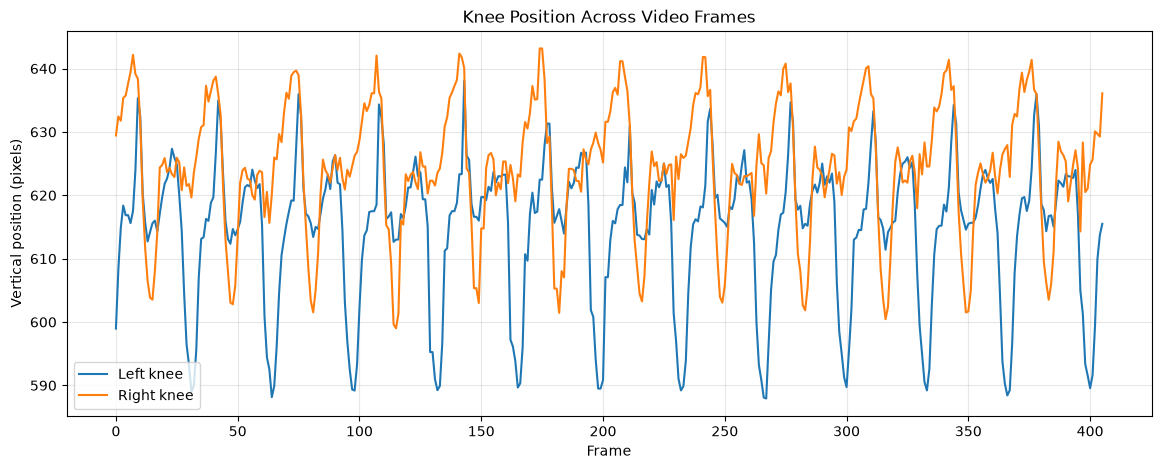

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    pose[("left_knee", "y")],
    label="Left knee"
)

plt.plot(
    pose[("right_knee", "y")],
    label="Right knee"
)

plt.xlabel("Frame")
plt.ylabel("Vertical position (pixels)")
plt.title("Knee Position Across Video Frames")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [13]:
def calculate_angle(a, b, c):
    a = np.array(a, dtype=float)
    b = np.array(b, dtype=float)
    c = np.array(c, dtype=float)

    ba = a - b
    bc = c - b

    denominator = np.linalg.norm(ba) * np.linalg.norm(bc)

    if denominator == 0:
        return np.nan

    cosine = np.dot(ba, bc) / denominator
    cosine = np.clip(cosine, -1.0, 1.0)

    return np.degrees(np.arccos(cosine))

In [14]:
def get_point(row, bodypart):
    return [
        row[(bodypart, "x")],
        row[(bodypart, "y")]
    ]

left_angles = []
right_angles = []

for _, row in pose.iterrows():

    left_points = [
        get_point(row, "left_hip"),
        get_point(row, "left_knee"),
        get_point(row, "left_ankle")
    ]

    right_points = [
        get_point(row, "right_hip"),
        get_point(row, "right_knee"),
        get_point(row, "right_ankle")
    ]

    left_angles.append(
        calculate_angle(*left_points)
        if np.isfinite(left_points).all()
        else np.nan
    )

    right_angles.append(
        calculate_angle(*right_points)
        if np.isfinite(right_points).all()
        else np.nan
    )

pose["left_knee_angle"] = left_angles
pose["right_knee_angle"] = right_angles

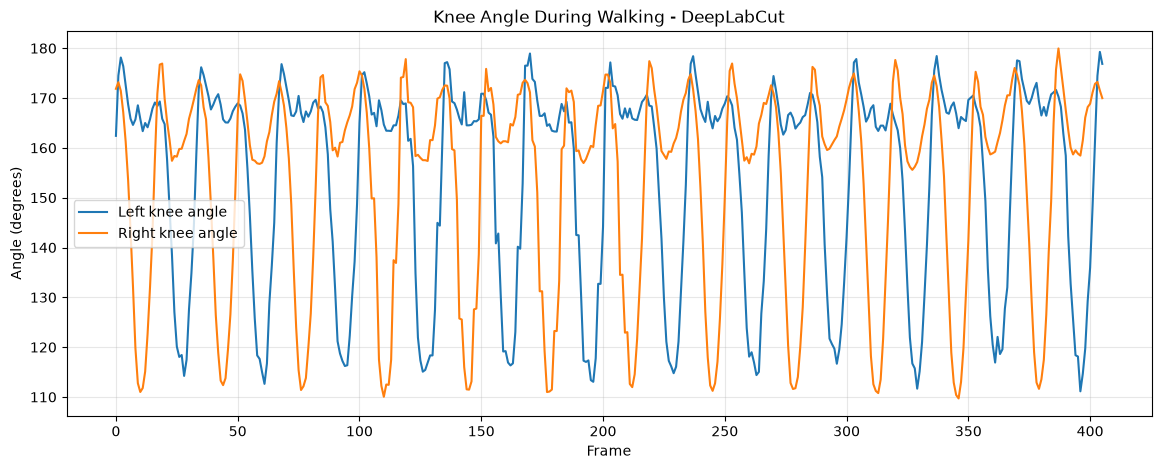

In [15]:
plt.figure(figsize=(14, 5))

plt.plot(
    pose["left_knee_angle"],
    label="Left knee angle"
)

plt.plot(
    pose["right_knee_angle"],
    label="Right knee angle"
)

plt.xlabel("Frame")
plt.ylabel("Angle (degrees)")
plt.title("Knee Angle During Walking - DeepLabCut")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Stage 5: MoveNet vs DeepLabCut Comparison

### Experimental Objective

We aim to compare the lower-body pose predictions generated by MoveNet and DeepLabCut on the same sagittal walking video.

Since the models may process different numbers of frames, their predictions must first be aligned using the original video frame indices.

MoveNet previously processed 82 frames, sampled every fifth frame. DeepLabCut processed all 406 frames.

For a fair comparison, we will extract DeepLabCut predictions at the exact frame indices used by MoveNet.

The comparison will focus on:

- Left and right hip positions.
- Left and right knee positions.
- Left and right ankle positions.
- Prediction confidence and detection availability.
- Knee-angle trajectories.

This experiment evaluates model agreement, not absolute accuracy. Independent ground-truth measurements would be required to establish accuracy.

In [16]:
import numpy as np

total_frames = 406
sampling_interval = 5

comparison_frames = np.arange(
    0,
    total_frames,
    sampling_interval
)

print("Number of comparison frames:", len(comparison_frames))
print("Frame indices:", comparison_frames)

Number of comparison frames: 82
Frame indices: [  0   5  10  15  20  25  30  35  40  45  50  55  60  65  70  75  80  85
  90  95 100 105 110 115 120 125 130 135 140 145 150 155 160 165 170 175
 180 185 190 195 200 205 210 215 220 225 230 235 240 245 250 255 260 265
 270 275 280 285 290 295 300 305 310 315 320 325 330 335 340 345 350 355
 360 365 370 375 380 385 390 395 400 405]


In [20]:
dlc_comparison = (
    df[scorer][individual]
    .loc[comparison_frames, bodyparts]
    .copy()
)

dlc_comparison = dlc_comparison.mask(dlc_comparison < 0, np.nan)

print("DLC comparison shape:", dlc_comparison.shape)
display(dlc_comparison.head())

DLC comparison shape: (82, 18)


bodyparts     left_hip                           right_hip              \
coords               x           y likelihood            x           y   
0          1004.550354  458.164062   0.328049   985.644104  456.062500   
5          1005.218750  469.320312   0.334886   995.859375  467.242188   
10          987.010437  464.604156   0.356370  1010.250000  460.562500   
15          972.255188  462.802094   0.443948  1005.427063  457.776031   
20          977.812500  475.562500   0.570010  1011.328125  475.562500   

bodyparts               left_knee                          right_knee  \
coords    likelihood            x           y likelihood            x   
0           0.344354  1068.621582  598.968750   0.757320   958.335083   
5           0.347995  1061.375000  616.867188   0.514814   959.461792   
10          0.354835  1021.364563  632.333313   0.596698  1060.770874   
15          0.381875   972.255188  615.593750   0.610750  1095.895874   
20          0.422340   945.312500  621.812500   0.529912  1082.421875   

bodyparts                          left_ankle                         \
coords              y likelihood            x           y likelihood   
0          629.441406   0.511065  1090.678833  781.804688   0.629162   
5          637.648438   0.568311  1092.572876  801.820312   0.672154   
10         631.322937   0.697256  1013.281250  810.166687   0.577667   
15         603.531250   0.817965   931.041687  807.588562   0.549775   
20         625.875000   0.575165   854.921875  793.453125   0.684493   

bodyparts  right_ankle                         
coords               x           y likelihood  
0           899.515625  820.683594   0.511584  
5           830.510437  799.742188   0.564492  
10          896.072937  757.625000   0.470845  
15         1076.796875  805.578125   0.549143  
20         1134.218750  816.812500   0.778273

In [21]:
movenet_predictions = np.load(
    project_root / "data" / "processed" / "movenet_predictions.npy"
)

movenet_frames = np.load(
    project_root / "data" / "processed" / "movenet_frame_indices.npy"
)

print("MoveNet shape:", movenet_predictions.shape)
print("Frame indices:", movenet_frames.shape)

MoveNet shape: (82, 6, 3)
Frame indices: (82,)


In [22]:
# Count frames with valid detections for each individual

individuals = df.columns.get_level_values("individuals").unique()
scorer = df.columns.get_level_values("scorer")[0]

detection_counts = {}

for individual in individuals:
    subject_data = df[scorer][individual]

    likelihoods = subject_data.xs(
        "likelihood",
        axis=1,
        level="coords"
    )

    valid_frames = (likelihoods > 0).any(axis=1).sum()
    detection_counts[individual] = valid_frames

detection_counts = pd.Series(detection_counts).sort_values(
    ascending=False
)

display(detection_counts)

animal0    406
animal1      0
animal2      0
animal3      0
animal4      0
animal5      0
animal6      0
animal7      0
animal8      0
animal9      0
dtype: int64

We select the six lower-body keypoints from `animal0` and retain only the 82 frames corresponding to MoveNet's sampled frames.

The extracted coordinates and confidence scores will be used for the model comparison.

In [23]:
# Select the confirmed subject
dlc_subject = df[scorer]["animal0"]

# Lower-body keypoints
bodyparts = [
    "left_hip", "right_hip",
    "left_knee", "right_knee",
    "left_ankle", "right_ankle"
]

# Select the same 82 frames used by MoveNet
dlc_comparison = dlc_subject.iloc[movenet_frames].loc[:, bodyparts].copy()

# Replace invalid negative values with NaN
dlc_comparison = dlc_comparison.mask(dlc_comparison < 0, np.nan)

print("DLC comparison shape:", dlc_comparison.shape)
print("MoveNet predictions shape:", movenet_predictions.shape)
print("Number of comparison frames:", len(movenet_frames))

display(dlc_comparison.head())

DLC comparison shape: (82, 18)
MoveNet predictions shape: (82, 6, 3)
Number of comparison frames: 82


bodyparts     left_hip                           right_hip              \
coords               x           y likelihood            x           y   
0          1004.550354  458.164062   0.328049   985.644104  456.062500   
5          1005.218750  469.320312   0.334886   995.859375  467.242188   
10          987.010437  464.604156   0.356370  1010.250000  460.562500   
15          972.255188  462.802094   0.443948  1005.427063  457.776031   
20          977.812500  475.562500   0.570010  1011.328125  475.562500   

bodyparts               left_knee                          right_knee  \
coords    likelihood            x           y likelihood            x   
0           0.344354  1068.621582  598.968750   0.757320   958.335083   
5           0.347995  1061.375000  616.867188   0.514814   959.461792   
10          0.354835  1021.364563  632.333313   0.596698  1060.770874   
15          0.381875   972.255188  615.593750   0.610750  1095.895874   
20          0.422340   945.312500  621.812500   0.529912  1082.421875   

bodyparts                          left_ankle                         \
coords              y likelihood            x           y likelihood   
0          629.441406   0.511065  1090.678833  781.804688   0.629162   
5          637.648438   0.568311  1092.572876  801.820312   0.672154   
10         631.322937   0.697256  1013.281250  810.166687   0.577667   
15         603.531250   0.817965   931.041687  807.588562   0.549775   
20         625.875000   0.575165   854.921875  793.453125   0.684493   

bodyparts  right_ankle                         
coords               x           y likelihood  
0           899.515625  820.683594   0.511584  
5           830.510437  799.742188   0.564492  
10          896.072937  757.625000   0.470845  
15         1076.796875  805.578125   0.549143  
20         1134.218750  816.812500   0.778273

In [26]:
movenet_angles = {
    "left_knee": [],
    "right_knee": []
}

for frame in movenet_predictions:

    lh, rh, lk, rk, la, ra = frame

    # Coordinates are [y, x, confidence].
    # For angle calculation, convert them to [x, y].

    lh_xy = lh[[1, 0]]
    rh_xy = rh[[1, 0]]
    lk_xy = lk[[1, 0]]
    rk_xy = rk[[1, 0]]
    la_xy = la[[1, 0]]
    ra_xy = ra[[1, 0]]

    # Left knee
    if min(lh[2], lk[2], la[2]) >= CONFIDENCE_THRESHOLD:
        left_angle = calculate_angle(lh_xy, lk_xy, la_xy)
    else:
        left_angle = np.nan

    # Right knee
    if min(rh[2], rk[2], ra[2]) >= CONFIDENCE_THRESHOLD:
        right_angle = calculate_angle(rh_xy, rk_xy, ra_xy)
    else:
        right_angle = np.nan

    movenet_angles["left_knee"].append(left_angle)
    movenet_angles["right_knee"].append(right_angle)

movenet_angles = pd.DataFrame(movenet_angles)

display(movenet_angles.head())

,left_knee,right_knee
0,176.049920,157.983128
1,NaN,168.628334
2,152.261251,138.739681
3,NaN,149.009532
4,168.945237,167.815755


In [25]:
dlc_angles = {
    "left_knee": [],
    "right_knee": []
}

for frame_idx in movenet_frames:

    frame = df[scorer]["animal0"].loc[frame_idx]

    def get_point(bodypart):
        x = frame[(bodypart, "x")]
        y = frame[(bodypart, "y")]
        confidence = frame[(bodypart, "likelihood")]

        if confidence < CONFIDENCE_THRESHOLD or x < 0 or y < 0:
            return None

        return np.array([x, y], dtype=float)

    # Left knee
    lh = get_point("left_hip")
    lk = get_point("left_knee")
    la = get_point("left_ankle")

    if all(point is not None for point in [lh, lk, la]):
        left_angle = calculate_angle(lh, lk, la)
    else:
        left_angle = np.nan

    # Right knee
    rh = get_point("right_hip")
    rk = get_point("right_knee")
    ra = get_point("right_ankle")

    if all(point is not None for point in [rh, rk, ra]):
        right_angle = calculate_angle(rh, rk, ra)
    else:
        right_angle = np.nan

    dlc_angles["left_knee"].append(left_angle)
    dlc_angles["right_knee"].append(right_angle)

dlc_angles = pd.DataFrame(dlc_angles)

display(dlc_angles.head())

,left_knee,right_knee
0,162.411643,171.855073
1,168.737724,153.553306
2,165.822269,111.002268
3,167.884771,142.772553
4,164.756296,169.864843


In [27]:
comparison = pd.DataFrame({
    "frame": movenet_frames,

    "movenet_left": movenet_angles["left_knee"],
    "dlc_left": dlc_angles["left_knee"],

    "movenet_right": movenet_angles["right_knee"],
    "dlc_right": dlc_angles["right_knee"]
})

display(comparison.head())

,frame,movenet_left,dlc_left,movenet_right,dlc_right
0,0,176.049920,162.411643,157.983128,171.855073
1,5,NaN,168.737724,168.628334,153.553306
2,10,152.261251,165.822269,138.739681,111.002268
3,15,NaN,167.884771,149.009532,142.772553
4,20,168.945237,164.756296,167.815755,169.864843


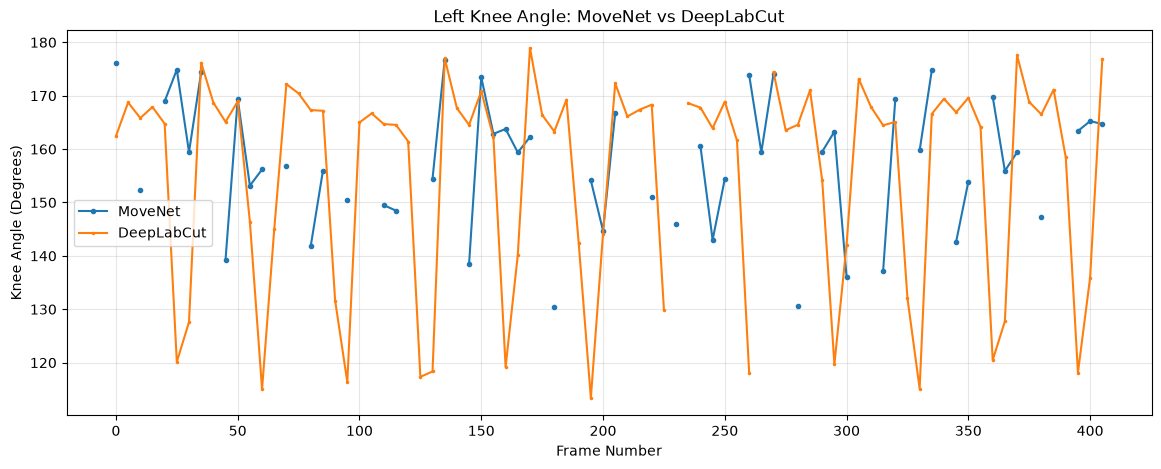

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    comparison["frame"],
    comparison["movenet_left"],
    label="MoveNet",
    marker="o",
    markersize=3
)

plt.plot(
    comparison["frame"],
    comparison["dlc_left"],
    label="DeepLabCut",
    marker=".",
    markersize=3
)

plt.title("Left Knee Angle: MoveNet vs DeepLabCut")
plt.xlabel("Frame Number")
plt.ylabel("Knee Angle (Degrees)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

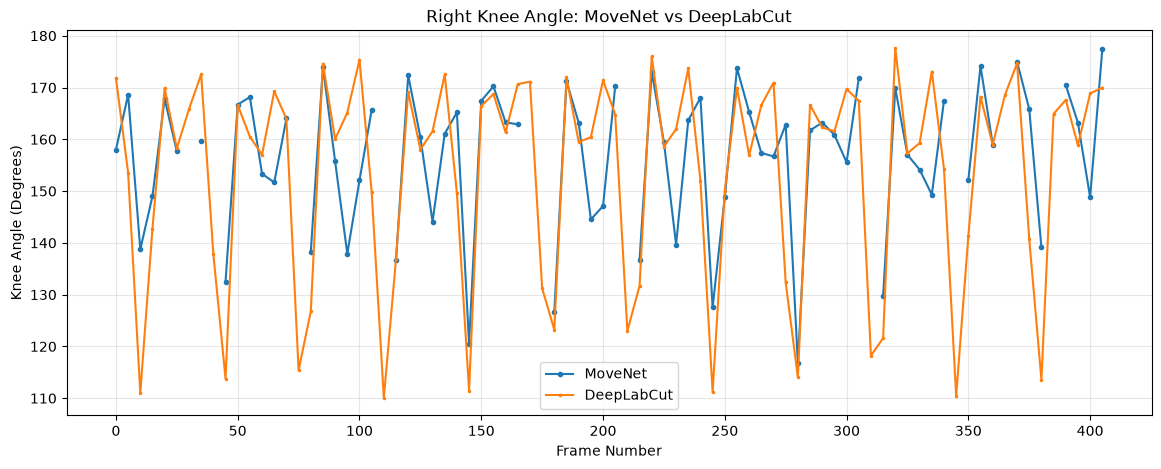

In [29]:
plt.figure(figsize=(14, 5))

plt.plot(
    comparison["frame"],
    comparison["movenet_right"],
    label="MoveNet",
    marker="o",
    markersize=3
)

plt.plot(
    comparison["frame"],
    comparison["dlc_right"],
    label="DeepLabCut",
    marker=".",
    markersize=3
)

plt.title("Right Knee Angle: MoveNet vs DeepLabCut")
plt.xlabel("Frame Number")
plt.ylabel("Knee Angle (Degrees)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [30]:
def compare_angles(movenet_series, dlc_series):
    paired = pd.DataFrame({
        "MoveNet": movenet_series,
        "DeepLabCut": dlc_series
    }).dropna()

    n = len(paired)

    if n == 0:
        return {
            "Valid paired frames": 0,
            "MAE (degrees)": np.nan,
            "RMSE (degrees)": np.nan,
            "Pearson correlation": np.nan
        }

    differences = paired["MoveNet"] - paired["DeepLabCut"]

    correlation = (
        paired["MoveNet"].corr(paired["DeepLabCut"])
        if n >= 2 else np.nan
    )

    return {
        "Valid paired frames": n,
        "MAE (degrees)": np.abs(differences).mean(),
        "RMSE (degrees)": np.sqrt(np.mean(differences ** 2)),
        "Pearson correlation": correlation
    }

In [31]:
results = {
    "Left Knee": compare_angles(
        movenet_angles["left_knee"],
        dlc_angles["left_knee"]
    ),

    "Right Knee": compare_angles(
        movenet_angles["right_knee"],
        dlc_angles["right_knee"]
    )
}

results_df = pd.DataFrame(results).T

display(results_df.round(3))

,Valid paired frames,MAE (degrees),RMSE (degrees),Pearson correlation
Left Knee,51.0,20.944,26.099,-0.073
Right Knee,71.0,9.341,12.493,0.732


In [32]:
coverage = pd.DataFrame({
    "MoveNet valid": [
        movenet_angles["left_knee"].notna().sum(),
        movenet_angles["right_knee"].notna().sum()
    ],
    "DeepLabCut valid": [
        dlc_angles["left_knee"].notna().sum(),
        dlc_angles["right_knee"].notna().sum()
    ],
}, index=["Left Knee", "Right Knee"])

display(coverage)

,MoveNet valid,DeepLabCut valid
Left Knee,53,80
Right Knee,71,82


In [33]:
def calculate_bias(movenet_series, dlc_series):
    paired = pd.DataFrame({
        "MoveNet": movenet_series,
        "DLC": dlc_series
    }).dropna()

    differences = paired["MoveNet"] - paired["DLC"]

    return pd.Series({
        "Mean bias (degrees)": differences.mean(),
        "Difference std (degrees)": differences.std(),
        "Minimum difference": differences.min(),
        "Maximum difference": differences.max()
    })


bias_results = pd.DataFrame({
    "Left Knee": calculate_bias(
        movenet_angles["left_knee"],
        dlc_angles["left_knee"]
    ),
    "Right Knee": calculate_bias(
        movenet_angles["right_knee"],
        dlc_angles["right_knee"]
    )
}).T

display(bias_results.round(3))

,Mean bias (degrees),Difference std (degrees),Minimum difference,Maximum difference
Left Knee,4.363,25.987,-33.934,55.784
Right Knee,0.309,12.578,-27.261,30.497


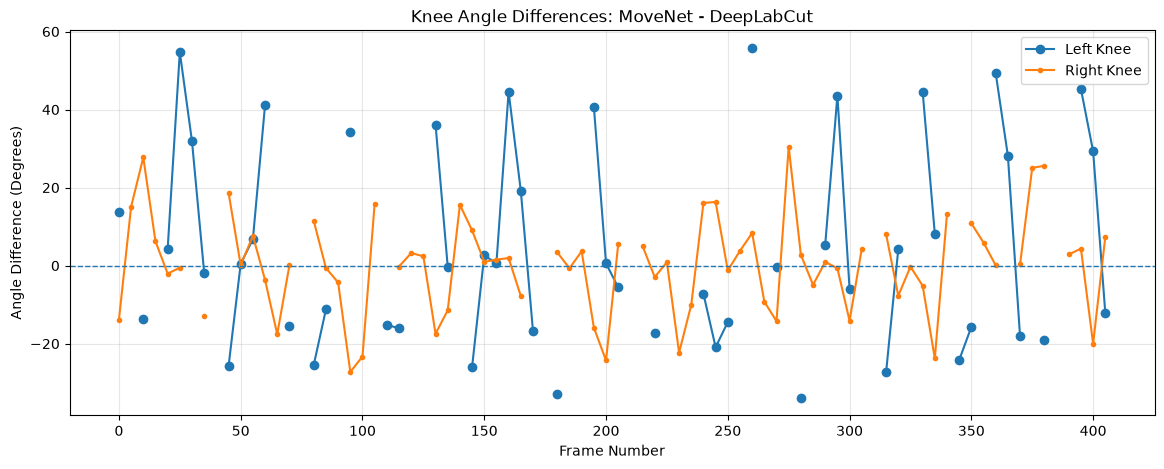

In [34]:
plt.figure(figsize=(14, 5))

plt.plot(
    comparison["frame"],
    comparison["movenet_left"] - comparison["dlc_left"],
    marker="o",
    label="Left Knee"
)

plt.plot(
    comparison["frame"],
    comparison["movenet_right"] - comparison["dlc_right"],
    marker=".",
    label="Right Knee"
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.title("Knee Angle Differences: MoveNet - DeepLabCut")
plt.xlabel("Frame Number")
plt.ylabel("Angle Difference (Degrees)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [35]:
from pathlib import Path

output_dir = project_root / "data" / "processed" / "comparison"
output_dir.mkdir(parents=True, exist_ok=True)

comparison.to_csv(
    output_dir / "movenet_dlc_knee_angles.csv",
    index=False
)

results_df.to_csv(
    output_dir / "agreement_metrics.csv"
)

bias_results.to_csv(
    output_dir / "bias_analysis.csv"
)

coverage.to_csv(
    output_dir / "detection_coverage.csv"
)

print("Comparison results saved to:", output_dir)

Comparison results saved to: /home/aghammd/Desktop/Programming/markerless-pose-estimation-lab/data/processed/comparison


# Stage 5: MoveNet vs DeepLabCut — Conclusion

## 1. Objective

The objective of this stage was to compare MoveNet and DeepLabCut for lower-body pose estimation and knee-angle calculation using the same sagittal-plane walking video.

Both models were evaluated on the same 82 sampled frames, selected at intervals of 5 frames from the original 406-frame video.

## 2. Methodology

- MoveNet Lightning was used as the baseline pose-estimation model.
- DeepLabCut 3.0.2 was used with the pretrained SuperAnimal Human model and RTMPose-X.
- Six lower-body landmarks were extracted: left/right hip, knee, and ankle.
- Knee angles were calculated using the hip–knee–ankle points.
- A confidence threshold of 0.3 was applied to both models.
- Only frames with valid angle estimates from both models were included in agreement calculations.

MoveNet coordinates were stored as `[y, x, confidence]` and reordered to `[x, y]` for angle calculations. DeepLabCut coordinates were already provided as `[x, y, likelihood]`.

## 3. Results

### Agreement metrics

| Metric | Left Knee | Right Knee |
|---|---:|---:|
| Valid paired frames | 51 | 71 |
| MAE (degrees) | 20.944 | 9.341 |
| RMSE (degrees) | 26.099 | 12.493 |
| Pearson correlation | -0.073 | 0.732 |
| Mean bias (degrees) | 4.363 | 0.309 |
| Difference standard deviation (degrees) | 25.987 | 12.578 |

### Detection coverage

| Model | Left Knee | Right Knee |
|---|---:|---:|
| MoveNet | 53/82 | 71/82 |
| DeepLabCut | 80/82 | 82/82 |

### Main observations

- The two models showed substantially better agreement for the right knee.
- Right-knee correlation was 0.732, while left-knee correlation was close to zero.
- DeepLabCut detected the left knee in more sampled frames than MoveNet.
- Left-leg occlusion, caused by the leg being behind the right leg, likely contributed to the weaker left-knee results.
- The right-knee mean bias was close to zero, but individual differences remained.

## 4. Limitations

1. The comparison used only one video and one subject.
2. The left leg was partially occluded during parts of the video.
3. Both models were evaluated using pretrained configurations.
4. No independent ground-truth measurements were available.
5. Agreement between two models does not establish anatomical accuracy.
6. The analysis used sampled frames rather than every frame for the MoveNet comparison.
7. The calculated angle is the geometric hip–knee–ankle angle. It should not automatically be interpreted as anatomical knee flexion without explicitly defining the angle convention.

## 5. Conclusion

In this experiment, MoveNet and DeepLabCut showed better agreement when estimating the right knee than the partially occluded left knee.

DeepLabCut also achieved higher detection coverage for both knees in the sampled frames.

These findings provide a baseline for further investigation, but they do not establish which model produces more accurate anatomical measurements.

## 6. Next Research Direction

The next stage will investigate whether alternative anatomical landmark configurations can improve knee-angle estimation.

The conventional hip–knee–ankle configuration will serve as the baseline. Alternative configurations may include additional landmarks along the thigh and shank or around the knee.

Before implementing a custom landmark model, the research question and desired landmark configuration should be clarified with the supervisor. Independent ground-truth measurements will also be needed to evaluate actual accuracy.